# WMC Practical Examination — Statement #12
## Throughput and Latency Measurement Using Network Tools (ping + Speedtest by Ookla)

**Problem statement.** Using the ping command and an online speed-testing tool such as Speedtest by Ookla, measure the latency, packet loss, download throughput and upload throughput of a Wi-Fi network, and analyse its performance.

(a) Repeat the ping test three times and record the observations in a table containing the test number, packets sent, packets received, packet loss, minimum RTT, maximum RTT and average RTT.

(b) Perform the speed test three times under similar network conditions, and record the ping, download throughput and upload throughput for each test. Calculate the average download and upload throughput. Compare the results and comment on the observed variations in network performance and packet loss.

---
**Aim:** To measure the latency, packet loss and throughput of a Wi-Fi link and analyse the variation between repeated tests.

## Theory (brief)
- **Latency / RTT** – time for a packet to reach the destination and the reply to come back, measured by `ping` (ICMP Echo Request / Echo Reply) in milliseconds.
- **Packet loss (%)** = (packets sent − packets received) / packets sent × 100.
- **Jitter** – variation of delay; here estimated as max RTT − min RTT.
- **Throughput** – the actual data rate achieved (Mbps). *Download* = server → client, *upload* = client → server. Speedtest by Ookla opens several parallel TCP connections to a nearby server to measure them, and also reports its own ping.
- Results vary between runs because Wi-Fi is a **shared, contention-based medium**: other users, interference, signal strength, background traffic and server load all change from moment to moment.

## Procedure
**(a) Ping** – connect the laptop to the Wi-Fi network and open Command Prompt:
```
ping -n 10 8.8.8.8          (Windows)
ping -c 10 8.8.8.8          (Linux / macOS)
```
Run it **three times** and copy each output into the ✏️ cell below (just paste the whole text — the notebook extracts the numbers). Or set `RUN_LIVE_PING = True` to let the notebook run the three pings itself.

**(b) Speed test** – open **speedtest.net** (or the Speedtest app), keep the same server, press **GO** three times, and note Ping (ms), Download (Mbps) and Upload (Mbps) for each run in the ✏️ cell.

> ⚠️ **The readings currently in this notebook are SAMPLE values** so that every table, graph and conclusion is visible.
> To use your own: open the cell marked **✏️ ENTER YOUR READINGS**, replace the values with what you recorded, set `SAMPLE_DATA = False`, then **Run All**. Every table, graph and conclusion below updates automatically.

In [1]:
import re, platform, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ✏️ ENTER YOUR READINGS
SAMPLE_DATA   = True
RUN_LIVE_PING = False          # True -> run 3 pings from this computer instead of using the pasted text
PING_HOST, PING_COUNT = "8.8.8.8", 10

# (a) paste the three ping outputs between the triple quotes
ping_outputs = [
"""Ping statistics for 8.8.8.8:
    Packets: Sent = 10, Received = 10, Lost = 0 (0% loss),
Approximate round trip times in milli-seconds:
    Minimum = 18ms, Maximum = 41ms, Average = 24ms""",
"""Ping statistics for 8.8.8.8:
    Packets: Sent = 10, Received = 9, Lost = 1 (10% loss),
Approximate round trip times in milli-seconds:
    Minimum = 19ms, Maximum = 87ms, Average = 33ms""",
"""Ping statistics for 8.8.8.8:
    Packets: Sent = 10, Received = 10, Lost = 0 (0% loss),
Approximate round trip times in milli-seconds:
    Minimum = 17ms, Maximum = 36ms, Average = 22ms""",
]

# (b) Speedtest results: (ping ms, download Mbps, upload Mbps) for the three runs
speedtests = [
    (21, 48.6, 22.4),
    (27, 41.3, 19.8),
    (19, 52.9, 23.1),
]
if SAMPLE_DATA:
    display(Markdown("<div style='padding:8px;border:2px solid #dd6b20;background:#fffaf0;color:#7b341e'>"
                     "<b>⚠ SAMPLE READINGS</b> – replace with your own measurements and set <code>SAMPLE_DATA = False</code>.</div>"))

<div style='padding:8px;border:2px solid #dd6b20;background:#fffaf0;color:#7b341e'><b>⚠ SAMPLE READINGS</b> – replace with your own measurements and set <code>SAMPLE_DATA = False</code>.</div>

In [2]:
def run_ping(host=PING_HOST, count=PING_COUNT):
    flag = "-n" if platform.system() == "Windows" else "-c"
    return subprocess.run(["ping", flag, str(count), host], capture_output=True, text=True).stdout

def parse_ping(txt):
    """Works with Windows and Linux/macOS ping summaries."""
    m = re.search(r"Sent = (\d+), Received = (\d+)", txt)                       # Windows
    if m:
        sent, recv = map(int, m.groups())
        r = re.search(r"Minimum = (\d+)ms, Maximum = (\d+)ms, Average = (\d+)ms", txt)
        mn, mx, av = map(float, r.groups()) if r else (np.nan,) * 3
    else:                                                                          # Linux / macOS
        m = re.search(r"(\d+) packets transmitted, (\d+) (?:packets )?received", txt)
        sent, recv = map(int, m.groups())
        r = re.search(r"= ([\d.]+)/([\d.]+)/([\d.]+)", txt)
        mn, av, mx = map(float, r.groups()) if r else (np.nan,) * 3
    return dict(sent=sent, received=recv, loss=100 * (sent - recv) / sent, min=mn, max=mx, avg=av)

if RUN_LIVE_PING:
    ping_outputs = [run_ping() for _ in range(3)]
pings = [parse_ping(t) for t in ping_outputs]

ping_df = pd.DataFrame({
    "Test No.": [1, 2, 3],
    "Packets sent": [p["sent"] for p in pings],
    "Packets received": [p["received"] for p in pings],
    "Packet loss (%)": [p["loss"] for p in pings],
    "Min RTT (ms)": [p["min"] for p in pings],
    "Max RTT (ms)": [p["max"] for p in pings],
    "Avg RTT (ms)": [p["avg"] for p in pings],
})
ping_df["Jitter ≈ max−min (ms)"] = ping_df["Max RTT (ms)"] - ping_df["Min RTT (ms)"]
display(Markdown(f"### (a) Ping observations — host `{PING_HOST}`"))
display(ping_df.style.hide(axis="index").format(precision=1)
        .highlight_max(subset=["Packet loss (%)", "Avg RTT (ms)"], color="#fed7d7"))

tot_sent, tot_recv = ping_df["Packets sent"].sum(), ping_df["Packets received"].sum()
print(f"Overall: {tot_sent} sent, {tot_recv} received → overall packet loss = {100*(tot_sent-tot_recv)/tot_sent:.1f} %")
print(f"Mean of average RTTs = {ping_df['Avg RTT (ms)'].mean():.1f} ms")

### (a) Ping observations — host `8.8.8.8`

Test No.,Packets sent,Packets received,Packet loss (%),Min RTT (ms),Max RTT (ms),Avg RTT (ms),Jitter ≈ max−min (ms)
1,10,10,0.0,18.0,41.0,24.0,23.0
2,10,9,10.0,19.0,87.0,33.0,68.0
3,10,10,0.0,17.0,36.0,22.0,19.0


Overall: 30 sent, 29 received → overall packet loss = 3.3 %
Mean of average RTTs = 26.3 ms


In [3]:
sp = pd.DataFrame(speedtests, columns=["Ping (ms)", "Download (Mbps)", "Upload (Mbps)"])
sp.insert(0, "Test No.", [1, 2, 3])
avg_row = pd.DataFrame([{"Test No.": "Average", **sp[["Ping (ms)", "Download (Mbps)", "Upload (Mbps)"]].mean().round(2).to_dict()}])
sp_table = pd.concat([sp, avg_row], ignore_index=True)
display(Markdown("### (b) Speed test observations"))
display(sp_table.style.hide(axis="index").format(precision=2)
        .apply(lambda r: ["font-weight:bold;background-color:#ebf8ff" if r["Test No."] == "Average" else "" for _ in r], axis=1))

avg_dl, avg_ul = sp["Download (Mbps)"].mean(), sp["Upload (Mbps)"].mean()
print(f"Average download throughput = ({' + '.join(f'{v:g}' for v in sp['Download (Mbps)'])}) / 3 = {avg_dl:.2f} Mbps")
print(f"Average upload throughput   = ({' + '.join(f'{v:g}' for v in sp['Upload (Mbps)'])}) / 3 = {avg_ul:.2f} Mbps")

### (b) Speed test observations

Test No.,Ping (ms),Download (Mbps),Upload (Mbps)
1,21.00,48.60,22.40
2,27.00,41.30,19.80
3,19.00,52.90,23.10
Average,22.33,47.60,21.77


Average download throughput = (48.6 + 41.3 + 52.9) / 3 = 47.60 Mbps
Average upload throughput   = (22.4 + 19.8 + 23.1) / 3 = 21.77 Mbps


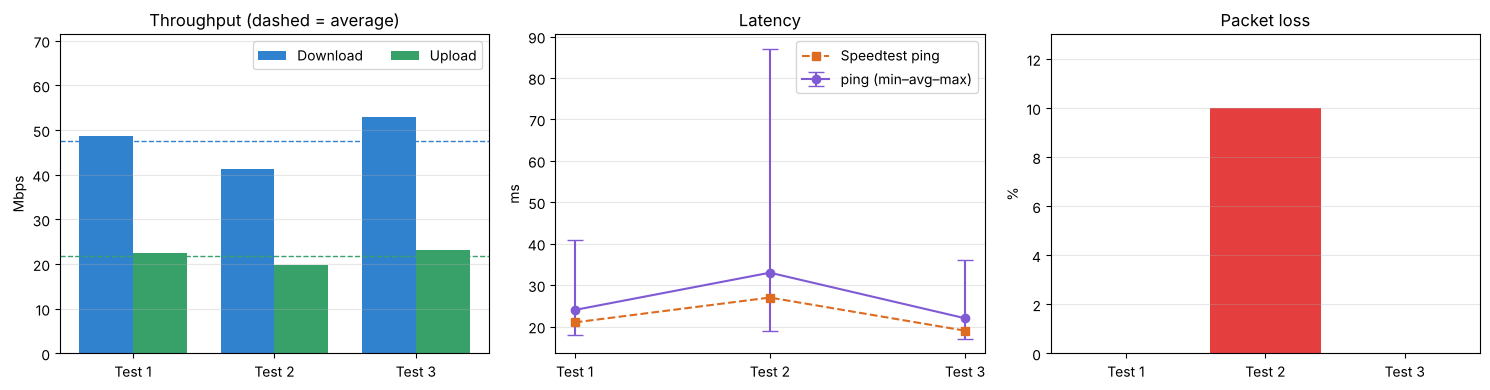

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
x = np.arange(3); w = 0.38
ax[0].bar(x - w/2, sp["Download (Mbps)"], w, label="Download", color="#3182ce")
ax[0].bar(x + w/2, sp["Upload (Mbps)"], w, label="Upload", color="#38a169")
ax[0].axhline(avg_dl, color="#3182ce", ls="--", lw=1); ax[0].axhline(avg_ul, color="#38a169", ls="--", lw=1)
ax[0].set_xticks(x, ["Test 1", "Test 2", "Test 3"]); ax[0].set_ylabel("Mbps"); ax[0].set_title("Throughput (dashed = average)"); ax[0].set_ylim(0, sp["Download (Mbps)"].max() * 1.35); ax[0].legend(loc="upper right", ncol=2)

ax[1].errorbar(x, ping_df["Avg RTT (ms)"], yerr=[ping_df["Avg RTT (ms)"] - ping_df["Min RTT (ms)"],
               ping_df["Max RTT (ms)"] - ping_df["Avg RTT (ms)"]], fmt="o-", capsize=6, color="#805ad5", label="ping (min–avg–max)")
ax[1].plot(x, sp["Ping (ms)"], "s--", color="#dd6b20", label="Speedtest ping")
ax[1].set_xticks(x, ["Test 1", "Test 2", "Test 3"]); ax[1].set_ylabel("ms"); ax[1].set_title("Latency"); ax[1].legend(loc="upper right")

ax[2].bar(x, ping_df["Packet loss (%)"], color=["#e53e3e" if v > 0 else "#48bb78" for v in ping_df["Packet loss (%)"]])
ax[2].set_xticks(x, ["Test 1", "Test 2", "Test 3"]); ax[2].set_ylabel("%"); ax[2].set_title("Packet loss")
ax[2].set_ylim(0, max(5, ping_df["Packet loss (%)"].max() * 1.3))
for a in ax: a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

In [5]:
def spread(s):
    return 100 * (s.max() - s.min()) / s.mean()

dl_var, ul_var, rtt_var = spread(sp["Download (Mbps)"]), spread(sp["Upload (Mbps)"]), spread(ping_df["Avg RTT (ms)"])
worst_dl = int(sp.loc[sp["Download (Mbps)"].idxmin(), "Test No."])
worst_rtt = int(ping_df.loc[ping_df["Avg RTT (ms)"].idxmax(), "Test No."])
loss_tests = ping_df.loc[ping_df["Packet loss (%)"] > 0, "Test No."].tolist()
level = lambda v: "small (stable link)" if v < 15 else "moderate" if v < 35 else "large (unstable link)"

lines = [
    f"- **Download** varied from {sp['Download (Mbps)'].min():g} to {sp['Download (Mbps)'].max():g} Mbps "
    f"(spread ≈ {dl_var:.0f}% of the average – {level(dl_var)}); average **{avg_dl:.2f} Mbps**.",
    f"- **Upload** varied from {sp['Upload (Mbps)'].min():g} to {sp['Upload (Mbps)'].max():g} Mbps "
    f"(spread ≈ {ul_var:.0f}% – {level(ul_var)}); average **{avg_ul:.2f} Mbps**. "
    f"Upload is {'lower' if avg_ul < avg_dl else 'higher'} than download (ratio ≈ {avg_dl/avg_ul:.1f} : 1), as is typical of asymmetric broadband plans.",
    f"- **Average RTT** varied from {ping_df['Avg RTT (ms)'].min():g} to {ping_df['Avg RTT (ms)'].max():g} ms (spread ≈ {rtt_var:.0f}%); "
    f"the largest jitter was {ping_df['Jitter ≈ max−min (ms)'].max():g} ms.",
]
if loss_tests:
    lines.append(f"- **Packet loss** occurred in test(s) {', '.join(map(str, loss_tests))}. "
                 f"The test with the highest RTT (test {worst_rtt}) " + ("also had the packet loss" if worst_rtt in loss_tests else "was a different test")
                 + f", and the lowest download speed was in test {worst_dl} — loss, higher delay and lower throughput tend to appear together during momentary congestion or interference on the Wi-Fi channel.")
else:
    lines.append("- **No packet loss** was observed in any ping test, indicating a reliable link.")
display(Markdown("### Comparison of results\n" + "\n".join(lines)))

### Comparison of results
- **Download** varied from 41.3 to 52.9 Mbps (spread ≈ 24% of the average – moderate); average **47.60 Mbps**.
- **Upload** varied from 19.8 to 23.1 Mbps (spread ≈ 15% – moderate); average **21.77 Mbps**. Upload is lower than download (ratio ≈ 2.2 : 1), as is typical of asymmetric broadband plans.
- **Average RTT** varied from 22 to 33 ms (spread ≈ 42%); the largest jitter was 68 ms.
- **Packet loss** occurred in test(s) 2. The test with the highest RTT (test 2) also had the packet loss, and the lowest download speed was in test 2 — loss, higher delay and lower throughput tend to appear together during momentary congestion or interference on the Wi-Fi channel.

## Result & Conclusion
Latency and packet loss were measured three times using `ping`, and download/upload throughput three times using Speedtest by Ookla; the tables above give each reading and the average download and upload throughput.

The three tests, taken under similar conditions, still **did not give identical results**: throughput and RTT fluctuate from run to run, and occasional packet loss appears together with higher RTT and lower throughput. This is because Wi-Fi is a shared, contention-based medium — the available capacity depends on the number of active users, co-/adjacent-channel interference, signal strength (RSSI), background traffic on the device and load on the ISP / test server. TCP throughput also falls when packets are lost, because lost segments are retransmitted and the sender reduces its congestion window.

**Conclusion:** A single measurement is not representative of a wireless link; repeated tests and averaging give a more reliable picture of its performance. Low average RTT, small jitter, zero packet loss and stable throughput indicate a good-quality Wi-Fi network.